# Combining windows: the sufficient-statistic addition

The six sufficient statistics are indexed by **velocity**, so windows on different wavelength
ranges (even different `dv`/`R`/instrument) evaluated on one velocity grid combine by simple
**addition** (`combine_stats`) into one joint fit with **shared `(v1, v2, a1, a2)`**. This
notebook makes that concrete: a window blind to the secondary cannot be fit on its own, but its
pure *primary* information **adds** to the blend window and sharpens the joint velocity estimate.

**Boundary (read §4):** this is valid only *within a single epoch*: all pooled windows must
share one true `(v1, v2)`. See [correlation engines § pooling orders](../../../docs/correlation_engines.md#pooling-orders).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# The TODCOR engine, its forward model, and the shared grid/FFT primitives
# (re-exported from unicor.dsp) all live in one namespace.
import todcor as tf

# The SPARTA figure style: data black steps, models red, one extra series
# blue, maps as grey-scale images with the peak black.
from sparta.plotting import (apply_style, DLNL_LABEL, map_colorbar, map_image, mark_fit,
                             mark_truth, plot_curve, plot_model)
apply_style()

# Speed of light, km/s
C = tf.C_KMS
# One Gaussian absorption or emission line: the building block of the templates
def gauss_line(wave, center, depth, fwhm_kms, emission=False):
    sigma = (fwhm_kms / 2.3548) * center / C
    prof = depth * np.exp(-0.5 * ((wave - center) / sigma) ** 2)
    return 1.0 + prof if emission else 1.0 - prof

# Synthetic rest-frame templates, finely sampled (0.5 km/s) and wider than the spectrum.
# Primary: an isolated line at 4634 PLUS a shallow line in the 4686 blend.
wave_t, _ = tf.log_lambda_grid(4560.0, 4760.0, 0.5)
tmpl1 = (wave_t, gauss_line(wave_t, 4634., 0.25, 120.) * gauss_line(wave_t, 4686., 0.15, 120.))
# Secondary: a broad emitter only at 4686.
tmpl2 = (wave_t, gauss_line(wave_t, 4686., 0.60, 400., emission=True))

# The observed spectrum: a uniform log-lambda grid (constant velocity step dv, km/s)
dv = 3.0
wave, u = tf.log_lambda_grid(4600.0, 4720.0, dv)
# Injected truth (velocities in km/s, light fractions) and noise level
v1t, v2t, a1t, a2t = 80.0, -160.0, 0.70, 0.55
sigma = 0.01
# Noisy composite: shift, scale and add the templates, then add white noise
comp = tf.composite_flux(wave, [tmpl1, tmpl2], [v1t, v2t], [a1t, a2t])
rng = np.random.default_rng(0)
data = comp + rng.normal(0, sigma, len(comp))
print(f"injected: v1={v1t:+.0f}  v2={v2t:+.0f}  a1={a1t}  a2={a2t}")

injected: v1=+80  v2=-160  a1=0.7  a2=0.55


## 1. Two windows on one shared velocity grid

Both windows are fit on the **same** `v1_grid`/`v2_grid` (a hard requirement of
`combine_stats`), but cover different wavelength ranges:

- **Window A**: the isolated primary line at 4634 Å (little secondary flux).
- **Window B**: the 4686 Å blend (both components).

`S11(v1)`/`S22(v2)` (the primary/secondary template powers over the window, at each trial
velocity) tell us which component each window can constrain:

In [2]:
v1g = np.arange(-300, 301, 3.0)     # SHARED velocity grids
v2g = np.arange(-400, 401, 3.0)

# Cut a wavelength window out of the spectrum; prepare_window extends the templates past it
def build_window(lo, hi):
    "Prepare one window (observed pixels lo-hi Å; templates extended by the largest velocity)."
    m = (wave > lo) & (wave < hi)
    return tf.prepare_window(wave[m], data[m], *tmpl1, *tmpl2, v_max=400.0)

# The two windows
winA = build_window(4610, 4660)     # primary-only line
winB = build_window(4665, 4715)     # the blend
# Sufficient statistics of each window, on the shared velocity grids
stA = tf.window_stats(winA.data_g, winA.g1, winA.g2, winA.dv, v1g, v2g, sigma=sigma)
stB = tf.window_stats(winB.data_g, winB.g1, winB.g2, winB.dv, v1g, v2g, sigma=sigma)
# Compare the template powers (largest over the trial velocities): A has no secondary power
for name, st, note in [("A (4634)", stA, "primary only"), ("B (4686)", stB, "both components")]:
    print(f"window {name}: max S11={st['S11'].max():9.3g}  max S22={st['S22'].max():9.3g}  ->  {note}")

window A (4634): max S11= 1.78e+04  max S22=        0  ->  primary only
window B (4686): max S11= 6.39e+03  max S22= 2.93e+05  ->  both components


## 2. Fit the blend window (B) alone

Window B sees both components, so on its own it already estimates `v1` and `v2`, but the two
are **correlated** and `v1` is loose (the primary is shallow inside the blend). Window A, by
contrast, has **no** secondary power: it cannot constrain `v2` at all. `prepare_window` finds
the secondary template flat (to round-off) over every pixel a shift can read and sets it to
exactly zero, so `S22 = 0` and the fit gives it amplitude 0. A alone is a primary-only fit:
`a2 = 0` and a flat map along `v2`, whose "peak" is just the first grid node. A's value is not as a standalone fit; it is the
pure primary information we will **add** in §3.

window B alone : v1 sigma=1.24  v2 sigma=0.90  rho=-0.20
window A alone : max S22 = 0e+00, a2 = 0 on every node (True), v1 = +81 km/s -- no secondary information


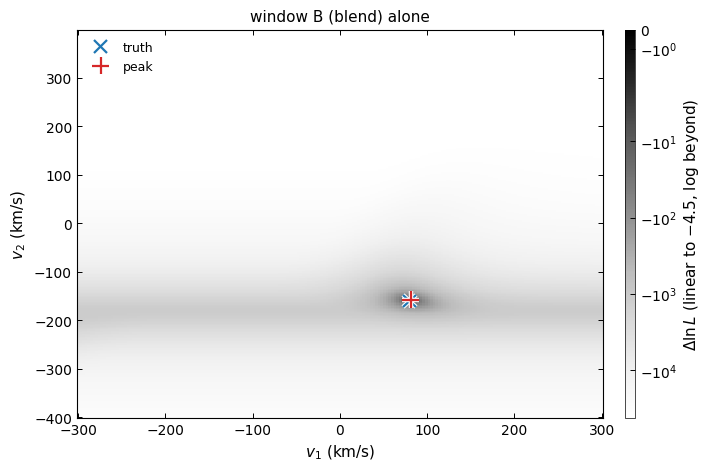

In [3]:
# Fit window B alone: the map, then the errors from the peak curvature
resB = tf.profile_from_stats(stB, v1g, v2g, nonneg=True)
crB = tf.crlb_from_map(resB["logL_profile"], v1g, v2g)
# A alone: the secondary has no lines there, so its amplitude is set to 0
resA = tf.profile_from_stats(stA, v1g, v2g, nonneg=True)
# B alone constrains both velocities, but they are correlated
print(f"window B alone : v1 sigma={crB['sigma_v1']:.2f}  v2 sigma={crB['sigma_v2']:.2f}  rho={crB['rho']:+.2f}")
# A alone: a2 = 0 everywhere, so the map is flat along v2 and its v2 'peak' means nothing
print(f"window A alone : max S22 = {stA['S22'].max():.0e}, a2 = {resA['best']['a2']:g} on every node "
      f"({np.all(resA['a2'] == 0)}), v1 = {resA['best']['v1']:+.0f} km/s -- no secondary information")

# Plot window B's map (peak black) with the truth and the fitted peak
fig, ax = plt.subplots(figsize=(7.0, 4.6))
logl = resB["logL_profile"].T                # the map is [v1, v2]; v1 along x
mesh = map_image(ax, v1g, v2g, logl, loglike=True)   # Delta lnL, peak black
map_colorbar(mesh, DLNL_LABEL)
mark_truth(ax, v1t, v2t, label="truth")
mark_fit(ax, resB["best"]["v1"], resB["best"]["v2"], label="peak")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.set_title("window B (blend) alone")
ax.legend(loc="upper left")
plt.show()

## 3. Add window A's primary information

`combine_stats([stA, stB])` sums the six statistics element-wise; because each window's χ² is
linear in them, the sum **is** the joint χ² with one shared `(v1, v2, a1, a2)` (each window
keeps its own free offset). Adding A's pure primary constraint tightens `v1` and de-correlates
the pair. The CRLB 1σ ellipses make it visible, drawn **at the truth** so we compare their *size
and tilt*, not their centring:

combined fit : v1=+81.0  v2=-160.0  a1=0.70  a2=0.55
truth        : v1=+80.0  v2=-160.0  a1=0.70  a2=0.55
v1 sigma : B alone 1.24  ->  A+B 0.65 km/s
corr rho : B alone -0.20  ->  A+B -0.08


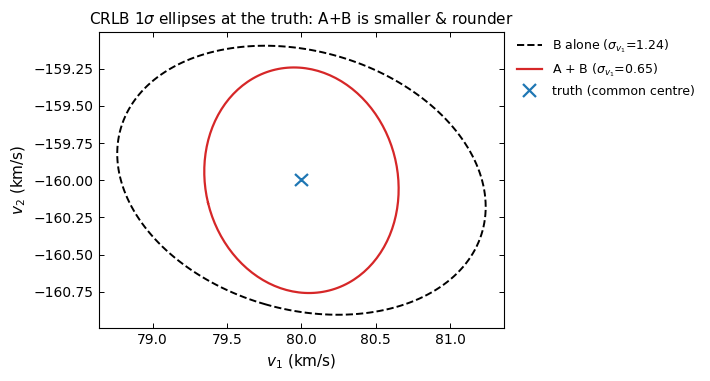

In [4]:
# Add the statistics of the two windows (combine_stats) and fit the joint map
stAB = tf.combine_stats([stA, stB])
resAB = tf.profile_from_stats(stAB, v1g, v2g, nonneg=True)
crAB = tf.crlb_from_map(resAB["logL_profile"], v1g, v2g)
bb = resAB["best"]
# Compare the joint fit with the truth, and its errors with B alone
print(f"combined fit : v1={bb['v1']:+.1f}  v2={bb['v2']:+.1f}  a1={bb['a1']:.2f}  a2={bb['a2']:.2f}")
print(f"truth        : v1={v1t:+.1f}  v2={v2t:+.1f}  a1={a1t:.2f}  a2={a2t:.2f}")
print(f"v1 sigma : B alone {crB['sigma_v1']:.2f}  ->  A+B {crAB['sigma_v1']:.2f} km/s")
print(f"corr rho : B alone {crB['rho']:+.2f}  ->  A+B {crAB['rho']:+.2f}")

th = np.linspace(0, 2*np.pi, 200)
# Points of a CRLB 1-sigma error ellipse, centred on the truth
def ellipse(cr):
    "1-sigma error ellipse, drawn at the truth to compare shape (not centring)."
    val, vec = np.linalg.eigh(cr["cov"])
    e = vec @ (np.sqrt(val)[:, None] * np.vstack([np.cos(th), np.sin(th)]))
    return v1t + e[0], v2t + e[1]

# Plot the ellipses of B alone and of A+B
fig, ax = plt.subplots(figsize=(7.0, 4.4))
xB, yB = ellipse(crB); xA, yA = ellipse(crAB)
plot_curve(ax, xB, yB, lw=1.4, ls="--", label=f"B alone ($\\sigma_{{v_1}}$={crB['sigma_v1']:.2f})")
plot_model(ax, xA, yA, lw=1.6, label=f"A + B ($\\sigma_{{v_1}}$={crAB['sigma_v1']:.2f})")
mark_truth(ax, v1t, v2t, label="truth (common centre)")
ax.set_xlabel("$v_1$ (km/s)"); ax.set_ylabel("$v_2$ (km/s)")
ax.set_title("CRLB 1$\\sigma$ ellipses at the truth: A+B is smaller & rounder")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0); ax.set_aspect("equal")
plt.show()

## 4. The boundary: what you may and may not add

`combine_stats` is powerful but has two constraints, plus one modelling caveat:

1. **Same velocity grid.** The `b1`/`b2`/`A12` arrays are summed element-wise, so every pooled
   window must be evaluated on the *identical* `v1_grid`/`v2_grid` (the `dv`/`R`/instrument may
   still differ; the shapes are checked, the values are not).
2. **Same epoch, never across epochs.** All pooled windows must share one true `(v1, v2)`.
   Different epochs have different velocities (orbital motion), so a shared-`v` fit across
   epochs is meaningless. To build an orbit you fit **each epoch** separately (pooling that
   epoch's lines), then feed the per-epoch velocities to the orbit fit.
3. **Shared amplitudes are an approximation.** One global `(a1, a2)` is shared across all
   pooled lines. For chemically-distinct lines (an absorption primary vs an emission
   secondary), or two stars of different temperature, the light/line-strength ratio changes
   from window to window. The alternative keeps the velocities shared and gives every window
   its own `(a1, a2)`: `profile_per_window` profiles each window's amplitudes, then sums the
   windows' χ² maps (`amplitudes='per_order'` in `joint_fit` and `CCF2d`). It costs two free
   parameters per window, so with a constant ratio, as here, it is looser:

In [5]:
# Each window its own (a1, a2); the velocities stay shared
resP = tf.profile_per_window([stA, stB], None, v1g, v2g, nonneg=True)
crP = tf.crlb_from_map(resP["logL_profile"], v1g, v2g)
bp = resP["best"]
# Each window's a1; only B's a2 (A's is as unconstrained as in §2)
v1P, v2P = crP["peak_refined"]
print(f"per window   : v1={v1P:+.1f}  v2={v2P:+.1f}  "
      f"a1 (A, B) = {bp['a1'][0]:.2f}, {bp['a1'][1]:.2f}  a2 (B) = {bp['a2'][1]:.2f}")
print(f"v1 sigma : shared {crAB['sigma_v1']:.2f}  ->  per window {crP['sigma_v1']:.2f} km/s;  "
      f"v2 sigma : shared {crAB['sigma_v2']:.2f}  ->  per window {crP['sigma_v2']:.2f} km/s")

per window   : v1=+80.2  v2=-158.4  a1 (A, B) = 0.70, 0.75  a2 (B) = 0.55
v1 sigma : shared 0.65  ->  per window 0.65 km/s;  v2 sigma : shared 0.76  ->  per window 0.89 km/s


## Summary

Pooling windows is just **adding their sufficient statistics**: a window blind to one component
(`S22 = 0`) contributes nothing to that velocity, but combined with a window that sees it, the
joint fit pins both velocities. Do it **within one epoch, on a shared velocity grid**; never
across epochs. When the light ratio differs between windows, give each its own amplitudes
(`profile_per_window`).

This closes the TODCOR set: `01_method` (the derivation), `02` (a single applied fit + CRLB), and
`03` (combination). The canonical written spec is [`todcor_method.md`](../../../packages/todcor/docs/todcor_method.md); the real-data
application it was extracted from (WR 2) lives in the parent research repository.